# Feature selection for y_ny
L1-penalized logistic regression ("lasso for classification"): like ridge, but the L1 penalty pushes useless features' weights to exactly 0.
C (inverse penalty strength) is picked by time-series cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, accuracy_score

# AUC vs number of features, adding them in order of |L1 weight| (most important first)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [2]:
# same prep + chronological split as PCA.ipynb
data = pd.read_feather("../data/final_data_ny.feather")
y = data[("y_ny", "")]
X = data.drop(columns=["y_ny", "ret_ny"], level=0).select_dtypes("number")
X.columns = ["_".join(filter(None, map(str, c))) for c in X.columns]  # flatten MultiIndex
X = X.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how="all").ffill().dropna()
y = y.loc[X.index].astype(int)

TEST_START = X.index[-int(len(data) * 0.2)]
X_train, X_test = X.loc[X.index < TEST_START], X.loc[TEST_START:]
y_train, y_test = y.loc[X_train.index], y.loc[X_test.index]
print("train:", X_train.shape, "test:", X_test.shape, "| share of up days (train):", round(y_train.mean(), 3))

train: (578, 126) test: (144, 126) | share of up days (train): 0.555


In [3]:
# TimeSeriesSplit: each fold trains on the past and validates on the next block, no shuffling (no look-ahead)
model = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=np.logspace(-3, 1, 30),   # small C = strong penalty = fewer features
        l1_ratios=[1.0],             # pure L1 (lasso)
        solver="saga",
        cv=TimeSeriesSplit(n_splits=5),
        scoring="roc_auc",
        max_iter=10000,
    ),
).fit(X_train, y_train)

c:\Users\salva\Desktop\Uni\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


In [4]:
lr = model[-1]
cv_auc = lr.scores_[1].mean(axis=0).max()
p_test = model.predict_proba(X_test)[:, 1]
print(f"best C: {lr.C_[0]:.4f}")
print(f"CV AUC:   {cv_auc:.3f}  ")
print(f"test AUC: {roc_auc_score(y_test, p_test):.3f}")
print(f"test acc: {accuracy_score(y_test, p_test > 0.5):.3f}   vs always-up baseline {y_test.mean():.3f}")

best C: 1.0826
CV AUC:   0.520  
test AUC: 0.510
test acc: 0.479   vs always-up baseline 0.569


104 / 126 features kept


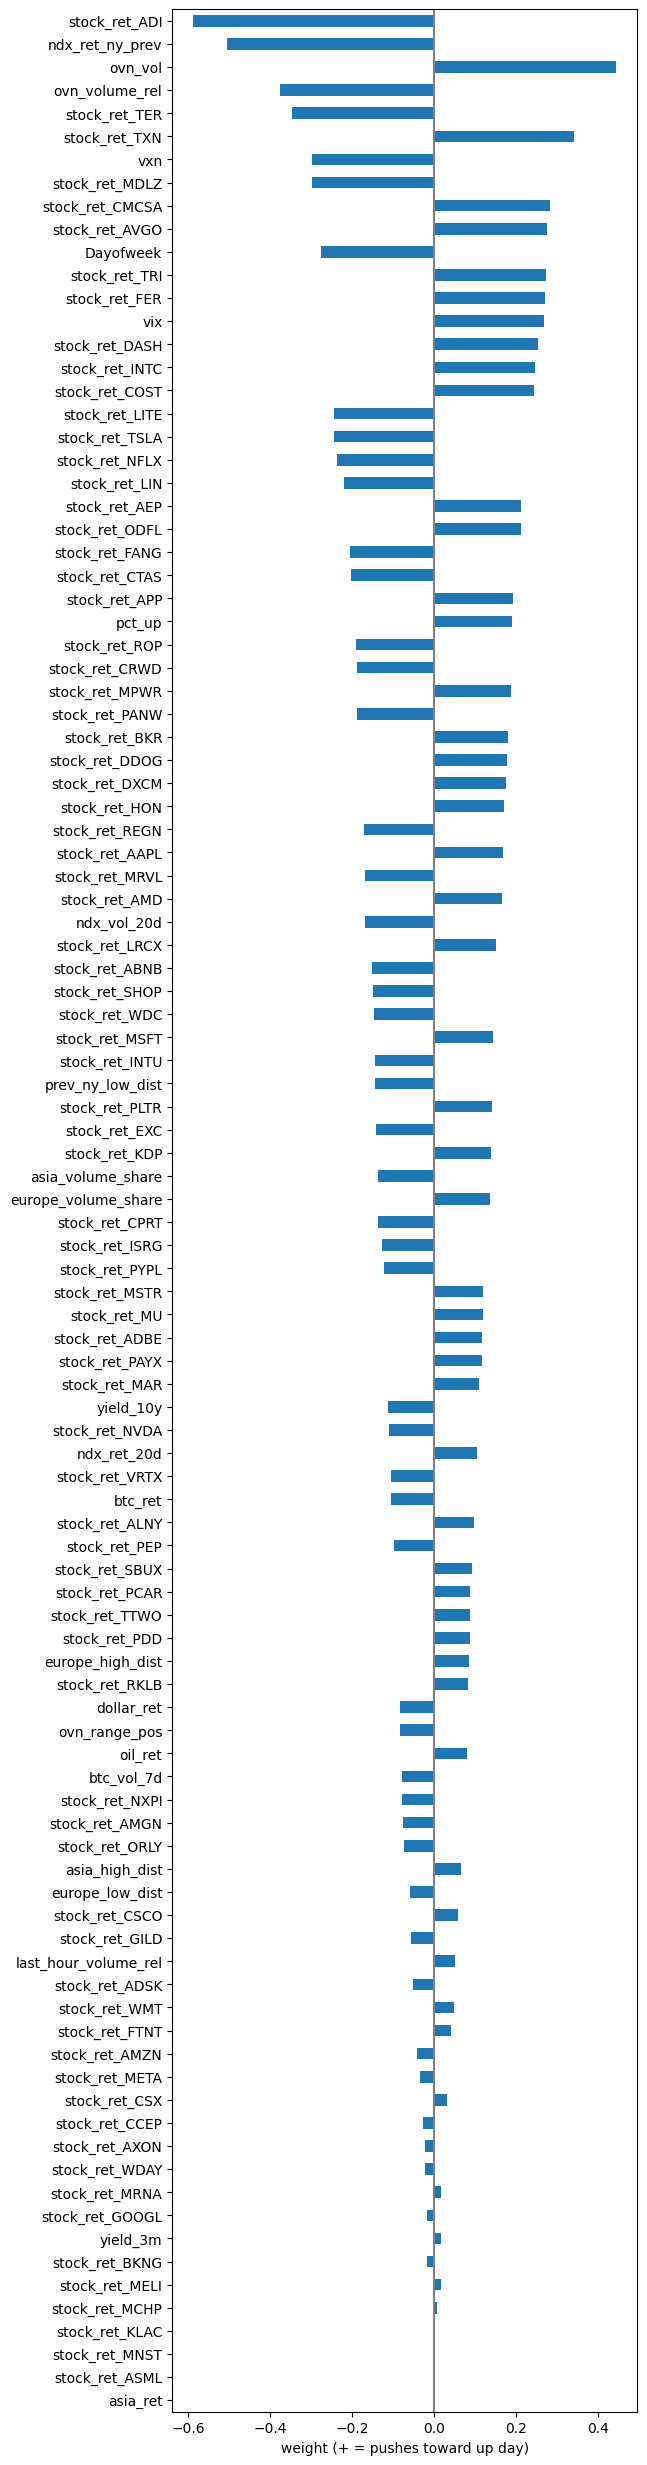

stock_ret_ADI     -0.587052
ndx_ret_ny_prev   -0.504866
ovn_vol            0.444839
ovn_volume_rel    -0.374969
stock_ret_TER     -0.347016
                     ...   
stock_ret_MCHP     0.008510
stock_ret_KLAC    -0.002968
stock_ret_MNST    -0.002818
stock_ret_ASML     0.002121
asia_ret          -0.000281
Length: 104, dtype: float64

In [5]:
# features kept by L1 (non-zero weight), on standardized scale so sizes are comparable
coef = pd.Series(lr.coef_[0], index=X.columns)
selected = coef[coef != 0].sort_values(key=abs, ascending=False)
print(f"{len(selected)} / {len(coef)} features kept")

selected.iloc[::-1].plot.barh(figsize=(6, max(2, 0.3 * len(selected))))
plt.axvline(0, c="grey"); plt.xlabel("weight (+ = pushes toward up day)")
plt.show()
selected

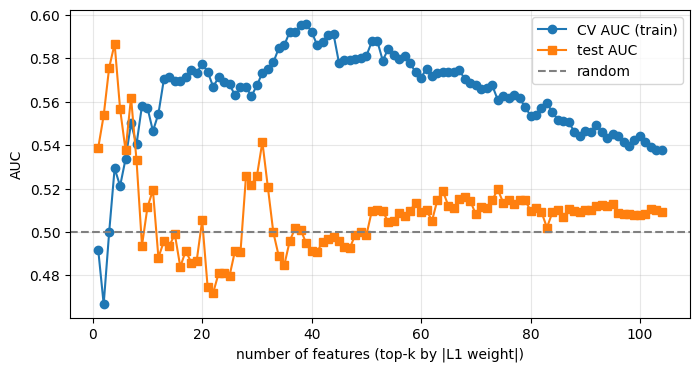

best k (CV): 39


In [6]:

ranked = selected.index
ks = range(1, len(ranked) + 1)
cv_aucs, test_aucs = [], []
for k in ks:
    cols = ranked[:k]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
    cv_aucs.append(cross_val_score(m, X_train[cols], y_train, cv=TimeSeriesSplit(n_splits=5), scoring="roc_auc").mean())
    test_aucs.append(roc_auc_score(y_test, m.fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]))

plt.figure(figsize=(8, 4))
plt.plot(ks, cv_aucs, "o-", label="CV AUC (train)")
plt.plot(ks, test_aucs, "s-", label="test AUC")
plt.axhline(0.5, c="grey", ls="--", label="random")
plt.xlabel("number of features (top-k by |L1 weight|)"); plt.ylabel("AUC")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print("best k (CV):", ks[int(np.argmax(cv_aucs))])

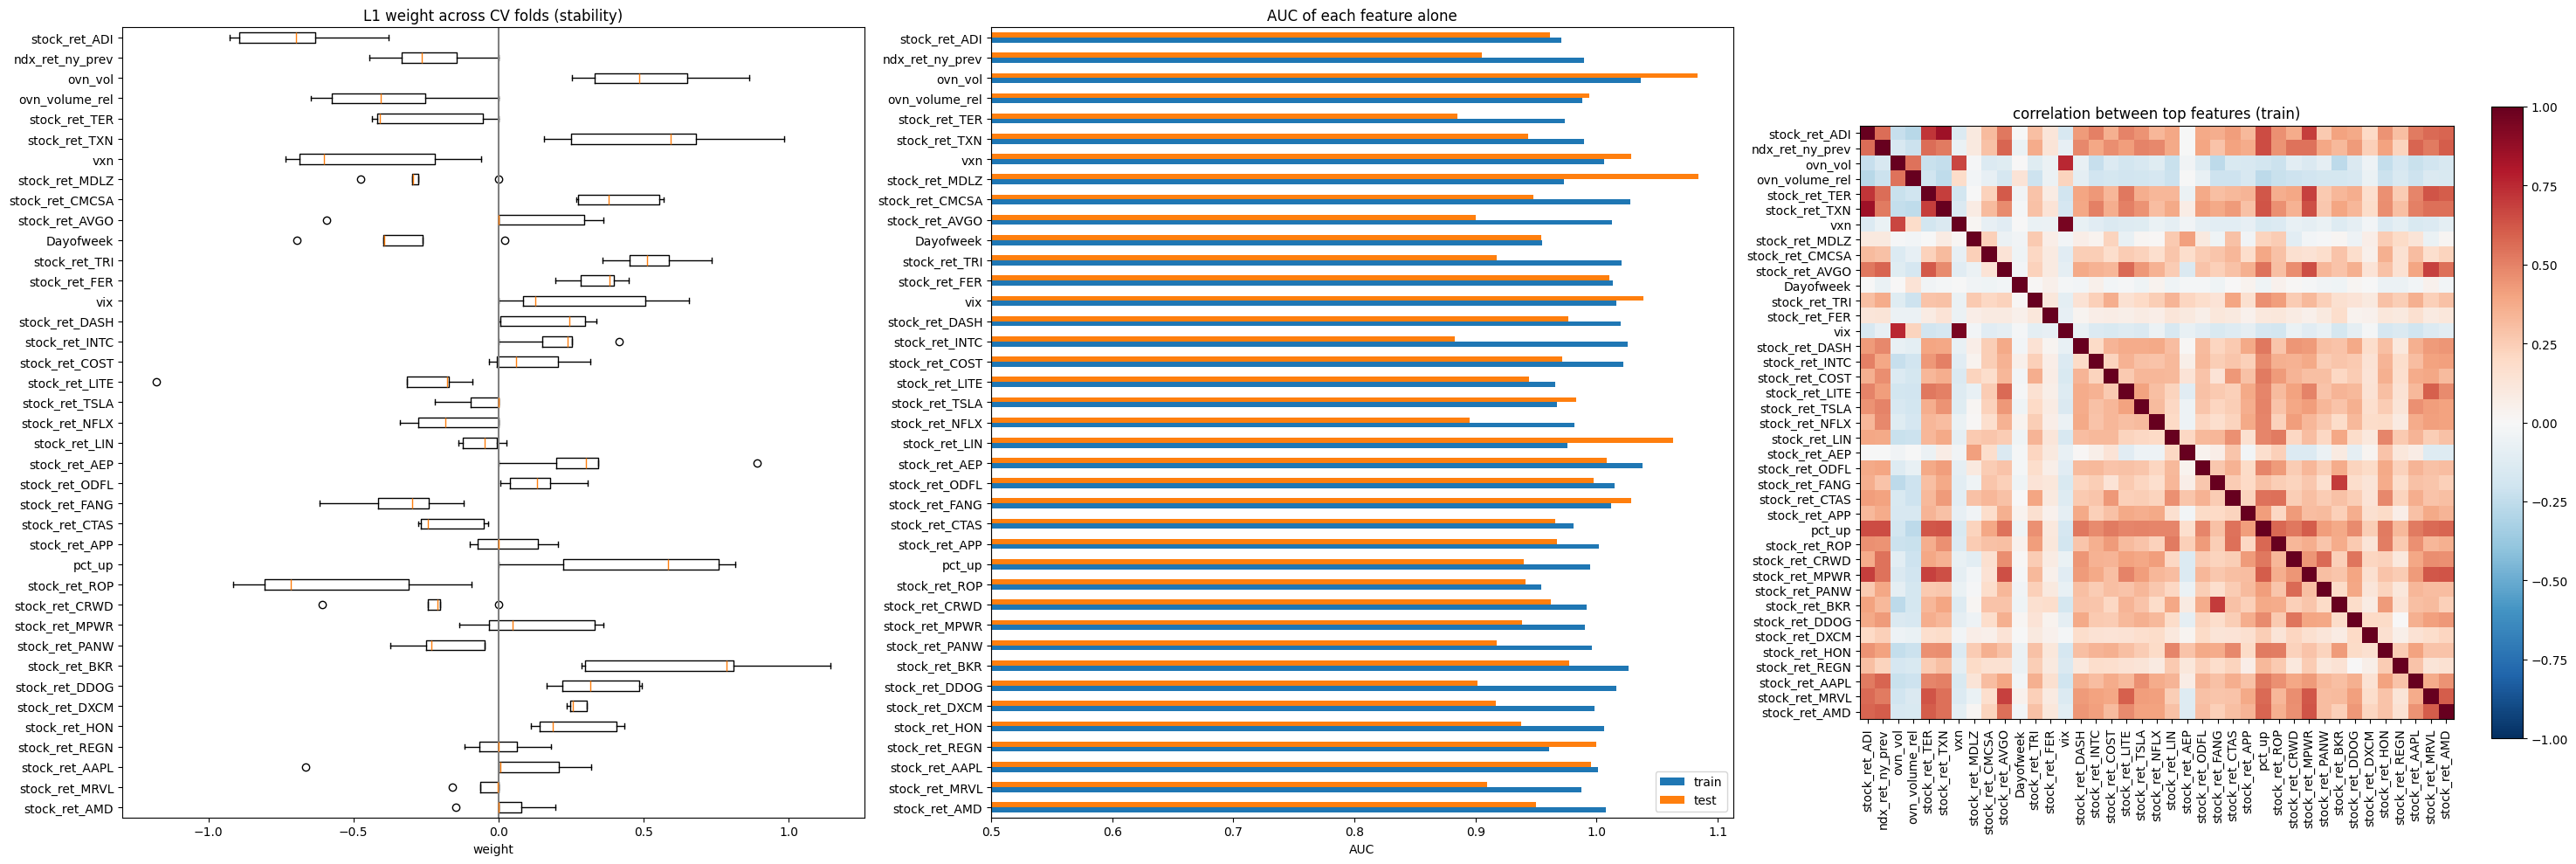

,train,test,weight,sign_consistent
stock_ret_ADI,0.471157,0.461251,-0.587052,1.0
ndx_ret_ny_prev,0.489872,0.405193,-0.504866,0.8
ovn_vol,0.536553,0.583202,0.444839,1.0
ovn_volume_rel,0.488321,0.494296,-0.374969,0.8
stock_ret_TER,0.473581,0.384736,-0.347016,0.8
stock_ret_TXN,0.489642,0.443843,0.341468,1.0
vxn,0.506594,0.528816,-0.297536,1.0
stock_ret_MDLZ,0.473060,0.583792,-0.297480,0.8
stock_ret_CMCSA,0.527728,0.448072,0.283542,1.0
stock_ret_AVGO,0.513073,0.400079,0.276303,0.4


In [7]:
# Understanding the top features
TOP = 39
top = selected.index[:TOP]
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

# 1) weight stability: refit the L1 model (best C) on each time-series fold
#    a useful feature keeps the same sign and a similar size in every fold
fold_coefs = []
for tr, _ in TimeSeriesSplit(n_splits=5).split(X_train):
    m = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver="saga", C=lr.C_[0], max_iter=10000))
    m.fit(X_train.iloc[tr], y_train.iloc[tr])
    fold_coefs.append(pd.Series(m[-1].coef_[0], index=X.columns)[top])
fold_coefs = pd.DataFrame(fold_coefs)
axes[0].boxplot(fold_coefs[top[::-1]].values, vert=False, tick_labels=top[::-1])
axes[0].axvline(0, c="grey"); axes[0].set_title("L1 weight across CV folds (stability)")
axes[0].set_xlabel("weight")

# 2) univariate AUC of each feature alone, train vs test (0.5 = useless, <0.5 = negative relation)
uni = pd.DataFrame({
    "train": [roc_auc_score(y_train, X_train[c]) for c in top],
    "test":  [roc_auc_score(y_test,  X_test[c])  for c in top],
}, index=top)
uni[::-1].plot.barh(ax=axes[1], left=0.5)  # bars start at 0.5 so direction is visible
axes[1].axvline(0.5, c="grey"); axes[1].set_title("AUC of each feature alone")
axes[1].set_xlabel("AUC")

# 3) correlation between top features: highly correlated pairs carry the same information
corr = X_train[top].corr()
im = axes[2].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[2].set_xticks(range(TOP), top, rotation=90); axes[2].set_yticks(range(TOP), top)
axes[2].set_title("correlation between top features (train)")
fig.colorbar(im, ax=axes[2], shrink=0.8)

plt.tight_layout(); plt.show()
uni.assign(weight=selected[top], sign_consistent=(np.sign(fold_coefs) == np.sign(selected[top])).mean().values)

## Choosing criteria : 

Stable sign. Keep features with sign_consistent == 1.0, meaning the weight points the same way in all 5 folds. AVGO, TSLA, APP and REGN, all at 0.4, flip direction from fold to fold, so drop them. One caveat: your folds use an expanding window and overlap, so 5/5 is weaker evidence than it looks.

No duplicates. If two kept features have |corr| > 0.8 with each other, keep only the more important one. Your heatmap shows which pairs these are.

How many to keep. Your "best k = 39" is just the highest point of a noisy curve. Use the 1-SE rule instead: take the smallest k whose CV AUC is within one standard error of the best. That usually leaves far fewer features and overfits less.

Optional sanity check. The feature's AUC on its own in train should fall on the same side of 0.5 as its weight's sign. Disagreement can be a real effect that only shows up alongside other features, but it's a reason to look at that feature more closely.


In [8]:
tbl = uni.assign(weight=selected[top],sign_consistent=(np.sign(fold_coefs) == np.sign(selected[top])).mean().values)
keep = tbl.index[tbl.sign_consistent == 1.0].tolist()

# drop near-duplicates, walking in importance order
c = X_train[keep].corr().abs()
final = []
for f in keep:
    if all(c.loc[f, g] < 0.8 for g in final):
        final.append(f)

m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
cv = cross_val_score(m, X_train[final], y_train, cv=TimeSeriesSplit(5), scoring="roc_auc")
print(len(final), "features | CV AUC", cv.mean().round(3), "±", cv.std().round(3))
print(final)


16 features | CV AUC 0.601 ± 0.072
['stock_ret_ADI', 'ovn_vol', 'vxn', 'stock_ret_CMCSA', 'stock_ret_TRI', 'stock_ret_FER', 'stock_ret_LITE', 'stock_ret_ODFL', 'stock_ret_FANG', 'stock_ret_CTAS', 'stock_ret_ROP', 'stock_ret_PANW', 'stock_ret_BKR', 'stock_ret_DDOG', 'stock_ret_DXCM', 'stock_ret_HON']


In [9]:
data_less_features = X[final]
data_less_features

,stock_ret_ADI,ovn_vol,vxn,stock_ret_CMCSA,stock_ret_TRI,stock_ret_FER,stock_ret_LITE,stock_ret_ODFL,stock_ret_FANG,stock_ret_CTAS,stock_ret_ROP,stock_ret_PANW,stock_ret_BKR,stock_ret_DDOG,stock_ret_DXCM,stock_ret_HON
Date,,,,,,,,,,,,,,,,
2023-01-26,-0.002431,0.000197,24.540001,0.008766,-0.002289,0.000000,0.006768,-0.001060,-0.001087,-0.007685,-0.004380,0.004226,0.027802,-0.040715,-0.019331,-0.001257
2023-01-27,0.013503,0.000179,25.010000,0.007701,0.004656,0.000000,0.009566,-0.004095,0.018925,0.009613,0.000495,0.047164,0.025479,0.071581,0.025162,0.012884
2023-01-30,0.000527,0.000215,24.570000,-0.020248,-0.003130,0.000000,0.007157,0.044538,0.007113,-0.008698,-0.023540,0.004202,-0.015848,0.016055,0.000656,-0.005845
2023-01-31,-0.011184,0.000227,26.250000,-0.009132,-0.002035,0.000000,-0.015711,-0.036333,-0.037939,-0.002817,-0.024792,-0.013547,-0.008986,-0.044887,-0.011592,-0.011355
2023-02-01,0.014924,0.000144,25.790001,0.002799,0.009968,0.000000,0.013719,0.034684,0.005352,0.017505,0.007692,0.006387,0.022946,0.013051,0.015053,0.013035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-05,-0.003528,0.000120,20.190001,-0.008420,-0.004627,-0.006336,0.078889,0.016817,0.007109,-0.003688,-0.002493,0.010531,0.002374,-0.018328,0.006149,-0.006430
2025-12-08,0.014430,0.000113,19.620001,0.004036,-0.001947,-0.000757,0.010800,0.010627,-0.005721,0.014672,0.006231,0.016020,-0.028256,-0.010447,0.003671,-0.004693
2025-12-09,-0.004183,0.000150,20.750000,-0.024464,-0.028355,0.009796,0.033091,-0.022619,-0.006833,-0.020394,-0.001901,-0.017708,-0.037482,0.018778,0.001983,0.003444


In [10]:
data_less_features.to_feather("../data/less_features.feather")